# Logistic Regression from Scratch

Logistic regression trained with gradient descent in NumPy, compared with scikit-learn on synthetic data.

## Goal

- Train the model and evaluate it with accuracy, precision, and recall.
- Compare it with a majority-class baseline and with scikit-learn.

In [52]:
import sys
sys.path.append("..")

import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression

from src.baseline import MajorityBaseline
from src.logistic_regression import MyLogisticRegression
from src.metrics import accuracy_score, precision_score, recall_score


def report(name, y_true, y_pred):
    """Print accuracy, precision and recall in percent."""
    print(f"{name:<9} accuracy={accuracy_score(y_true, y_pred) * 100:.1f}%  "
          f"precision={precision_score(y_true, y_pred) * 100:.1f}%  "
          f"recall={recall_score(y_true, y_pred) * 100:.1f}%")

## Data

1000 synthetic samples with 4 features. Class 1 makes up 30% of the data. The classes overlap: only the first two features carry information, the last two are noise. The first 800 samples are for training, the last 200 for testing.

In [53]:
SEED = 0
N_SAMPLES, N_POS, N_TRAIN = 1000, 300, 800
SHIFT = np.array([1.5, 1.0, 0.0, 0.0])

np.random.seed(SEED)
X0 = np.random.randn(N_SAMPLES - N_POS, 4)
X1 = np.random.randn(N_POS, 4) + SHIFT

X = np.vstack([X0, X1])
y = np.array([0] * (N_SAMPLES - N_POS) + [1] * N_POS)

idx = np.random.permutation(N_SAMPLES)
X, y = X[idx], y[idx]

X_train, X_test = X[:N_TRAIN], X[N_TRAIN:]
y_train, y_test = y[:N_TRAIN], y[N_TRAIN:]

## Baseline

Always predicts the majority class (0). Its accuracy is high only because the classes are imbalanced, and it never finds a positive sample.

In [54]:
baseline = MajorityBaseline()
baseline.fit(X_train, y_train)
baseline_pred = baseline.predict(X_test)

report("baseline:", y_test, baseline_pred)

baseline: accuracy=73.5%  precision=0.0%  recall=0.0%


## My Model

Gradient descent on the training set. The loss curve shows how training converges. The predictions are evaluated on the test set.

mine:     accuracy=85.5%  precision=76.1%  recall=66.0%


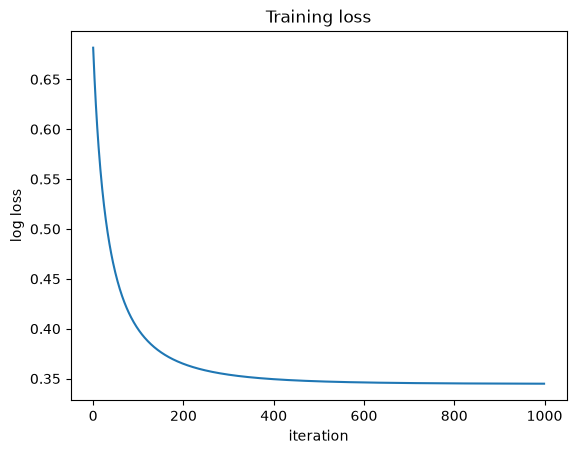

In [55]:
my_model = MyLogisticRegression().fit(X_train, y_train)
my_pred = my_model.predict(X_test)

report("mine:", y_test, my_pred)

plt.plot(my_model.losses)
plt.xlabel("iteration")
plt.ylabel("log loss")
plt.title("Training loss")
plt.show()

## Comparison with scikit-learn

The reference `LogisticRegression` with `penalty=None`: my model has no regularization yet, and scikit-learn applies L2 by default, which would change the weights. Both models are compared by metrics, weights, and predictions.

In [56]:
sk_model = LogisticRegression(C=np.inf, max_iter=1000).fit(X_train, y_train)
sk_pred = sk_model.predict(X_test)

report("sklearn:", y_test, sk_pred)

print(f"\nmine:    w={my_model.w.round(3)}  b={my_model.b:.3f}")
print(f"sklearn: w={sk_model.coef_[0].round(3)}  b={sk_model.intercept_[0]:.3f}")
print(f"Max weight difference: {np.abs(my_model.w - sk_model.coef_[0]).max():.2e}")
print(f"Predictions agree on {(my_pred == sk_pred).mean() * 100:.1f}% of test samples")

sklearn:  accuracy=85.5%  precision=76.1%  recall=66.0%

mine:    w=[ 1.508  1.234 -0.064 -0.11 ]  b=-2.478
sklearn: w=[ 1.56   1.279 -0.068 -0.113]  b=-2.569
Max weight difference: 5.22e-02
Predictions agree on 100.0% of test samples


## Takeaways

- Accuracy of the baseline is 73.5%, but its recall is 0. My model reaches 85.5% accuracy and 66.0% recall.
- My model matches scikit-learn: the maximum weight difference is 5.22e-02 and the predictions agree on 100.0% of samples.
- The first two weights are large and the last two are close to zero, so the model recognizes the noise features.
- Not covered yet: feature scaling, regularization, and the effect of the learning rate.